In [1]:
#DMV-4 : Real Estate Pricing

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load dataset
url = "https://raw.githubusercontent.com/datasets/house-prices-uk/master/data/data.csv"
df = pd.read_csv(url)

In [3]:
print("Original Data:")
print(df.head())
print(df.info())

Original Data:
         Date  Price (All)  Change (All)  Price (New)  Change (New)  \
0  1953-02-01       1891.0           NaN       2107.0           NaN   
1  1953-05-01       1891.0           NaN       2107.0           NaN   
2  1953-08-01       1881.0           NaN       2117.0           NaN   
3  1953-11-01       1872.0          -1.0       2117.0           0.5   
4  1954-02-01       1863.0          -1.5       2117.0           0.5   

   Price (Modern)  Change (Modern)  Price (Older)  Change (Older)  
0          2002.0              NaN         1542.0             NaN  
1          2002.0              NaN         1542.0             NaN  
2          2002.0              NaN         1524.0             NaN  
3          1975.0             -2.2         1542.0             1.2  
4          1957.0             -2.2         1524.0            -1.2  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290 entries, 0 to 289
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  


In [4]:
# Clean column names
df.columns = df.columns.str.replace(" ", "_")
df.columns = df.columns.str.replace("(", "", regex=False)
df.columns = df.columns.str.replace(")", "", regex=False)

In [5]:
# Remove duplicates
df = df.drop_duplicates()

In [6]:
# Handle missing values
df = df.dropna(subset=["Date", "Price_All"])

In [7]:
# Convert data types
df["Date"] = pd.to_datetime(df["Date"])
df["Price_All"] = pd.to_numeric(df["Price_All"])

In [8]:
# Filter data
df["Year"] = df["Date"].dt.year
filtered_df = df[df["Year"] >= 2000]

In [9]:
print("\nFiltered Data:")
print(filtered_df.head())


Filtered Data:
          Date  Price_All  Change_All  Price_New  Change_New  Price_Modern  \
188 2000-02-01    77698.0        15.1    89015.0        11.8       77208.0   
189 2000-05-01    81202.0        16.0    90383.0        11.7       80893.0   
190 2000-08-01    80935.0        11.8    92207.0         9.9       80756.0   
191 2000-11-01    81628.0         9.4    92950.0         7.9       81580.0   
192 2001-02-01    83976.0         8.1    95641.0         7.4       83297.0   

     Change_Modern  Price_Older  Change_Older  Year  
188           14.9      74285.0          16.5  2000  
189           16.3      77808.0          16.9  2000  
190           12.4      77930.0          12.9  2000  
191            9.8      78035.0           9.7  2000  
192            7.9      80656.0           8.6  2001  


In [10]:
# Feature engineering
df["Price_Difference"] = df["Price_New"] - df["Price_Older"]

# Calculate average price by year
yearly_price = df.groupby("Year")["Price_All"].mean()

In [11]:
print("\nAverage House Price by Year:")
print(yearly_price)


Average House Price by Year:
Year
1953      1883.75
1954      1862.75
1955      1927.75
1956      1996.00
1957      2025.50
          ...    
2021    243750.25
2022    267388.25
2023    259862.00
2024    265240.25
2025    271809.00
Name: Price_All, Length: 73, dtype: float64


In [12]:
# Handle outliers using IQR
Q1 = df["Price_All"].quantile(0.25)
Q3 = df["Price_All"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["Price_All"] = df["Price_All"].clip(lower, upper)

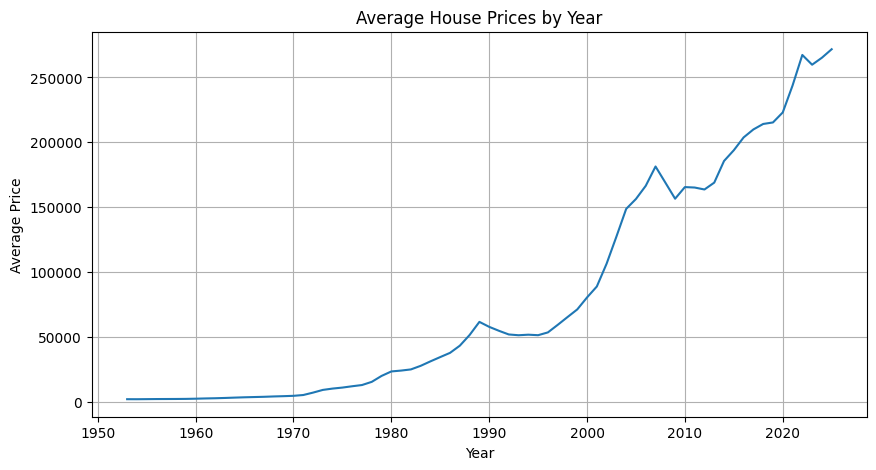

Data Wrangling Completed Successfully!


In [13]:
# Plotting Graph

plt.figure(figsize=(10, 5))
plt.plot(yearly_price.index, yearly_price.values)
plt.title("Average House Prices by Year")
plt.xlabel("Year")
plt.ylabel("Average Price")
plt.grid(True)
plt.show()

df.to_csv("Cleaned_House_Prices.csv", index=False)

print("Data Wrangling Completed Successfully!")